<a id="chapter-19"></a>

# Chapter 19 · Reinforcement Learning with Human Feedback / RLHF

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解偏好标签与 reward model
- 掌握 Bradley-Terry preference loss
- 认识 KL 约束和 reward hacking

**开始前最好已经会：**

- 掌握 actor-critic/PPO 主线
- 理解二分类交叉熵
- 知道 KL 正则的直觉


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Reward functions in complex environments | 为什么需要偏好 | 详细 |
| Theoretical method / RLHF and LLMs | Bradley-Terry、KL | 详细 |
| Initial A2C training | 实验闭环起点 | 源码路线 |
| Labeling process | UI、pair 采样与偏差 | 详细 |
| Reward model training | loss、验证 | 详细 |
| A2C + reward model / multi-round fine-tuning | 完整闭环 | 详细 |
| Overall results | 独立评价 | 详细 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

很多目标无法写成可靠规则：‘动作自然不自然’、‘回答有没有帮助’。能否让人只比较两个片段，再由模型学出奖励？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

先收集轨迹片段与人类偏好，再训练 reward model，最后让策略优化预测奖励，同时用 KL 或其他约束避免偏离参考策略太远。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\sigma^A,\sigma^B$ | 两个待比较轨迹片段 | 包含若干 observation/action |
| $r_\phi$ | reward model 的逐步评分 | 由偏好数据学习 |
| $R_A,R_B$ | 片段总预测分 | 逐步评分求和 |
| $\pi_{ref}$ | 参考策略 | 限制新策略漂移 |
| $\beta$ | KL 惩罚强度 | 对齐收益与保守程度权衡 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从相对偏好到概率

人类标签只说 A 比 B 好，不给绝对分数。Bradley-Terry 模型假设

$$P(A\succ B)=\frac{e^{R_A}}{e^{R_A}+e^{R_B}}
=\sigma(R_A-R_B)$$

只依赖分数差，所以给两个分数同时加常数不改变偏好概率。

### 2. preference loss

标签 $y=1$ 表示偏好 A，二元交叉熵为

$$L=-y\log\sigma(R_A-R_B)-(1-y)\log[1-\sigma(R_A-R_B)]$$

实现应使用 `binary_cross_entropy_with_logits(R_A-R_B, y)`，避免先 sigmoid 后 log 的数值不稳定。

### 3. 为什么策略不能只追 reward model

reward model 只在有限标注分布内可靠。策略会主动搜索其漏洞，产生人类不喜欢但预测高分的行为。常加入参考策略约束：

$$r_{total}=r_\phi-\beta[\log\pi_\theta(a|s)-\log\pi_{ref}(a|s)]$$

并持续让人检查策略找到的高分样本，形成迭代数据闭环。

### 4. 一个完整闭环

```text
初始策略 → 收集片段 → 人类比较 → 训练 reward model
    ↑                                  ↓
独立评估 ← 受 KL 约束的策略优化 ← 预测奖励
```


## 4. 手算一个最小例子


若 $R_A=2,R_B=1$，则 $P(A\succ B)=\sigma(1)\approx0.731$。若标签确实偏好 A，loss 为 $-\log0.731\approx0.313$。

若人类偏好 B，同一预测的 loss 为 $-\log(1-0.731)\approx1.313$，梯度会推动 $R_A-R_B$ 下降。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 偏好模型

两个片段 $\sigma^A,\sigma^B$ 的预测总分分别为 $R_A,R_B$：
$$P(A\succ B)=\frac{e^{R_A}}{e^{R_A}+e^{R_B}}=\sigma(R_A-R_B)$$

二元交叉熵训练 reward model。策略阶段常使用：
$$r_{total}=r_\phi-\beta\big(\log\pi_\theta(a|s)-\log\pi_{ref}(a|s)\big)$$

reward model 的高分不等于真实人类满意度，必须保留独立评估。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $R_A,R_B$ | `score_a`, `score_b` | 每个 pair 一个总分 |
| $R_A-R_B$ | `logits = score_a - score_b` | 偏好 logit |
| $y$ | `labels`，0/1 float | 人类偏好方向 |
| preference BCE | `binary_cross_entropy_with_logits` | 稳定的 sigmoid + BCE |
| $\log\pi_\theta-\log\pi_{ref}$ | 策略与参考的 token/action log-ratio | 样本级 KL 惩罚估计 |

**从公式过渡到代码时：**下面直接计算一批成对偏好的 stable logistic loss；label=1 表示偏好 A。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch
import torch.nn.functional as F

score_a = torch.tensor([2.0, -0.5, 1.0], requires_grad=True)
score_b = torch.tensor([1.0, 0.5, 1.5], requires_grad=True)
labels = torch.tensor([1.0, 0.0, 1.0])

logits = score_a - score_b
loss = F.binary_cross_entropy_with_logits(logits, labels)
loss.backward()
print("P(A preferred):", torch.sigmoid(logits).detach())
print("preference loss:", loss.item())


P(A preferred): tensor([0.7311, 0.2689, 0.3775])
preference loss: 0.53353351354599


### 怎样读运行结果

第一和第三对样本的标签偏好 A，但第三对中 A 分数更低，因此第三对会贡献较大纠正梯度。交换 A/B 并翻转标签，loss 应保持一致，这是很好的单元测试。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
1. 训练/准备初始 policy，收集 trajectory clips。
2. 成对展示 clips；记录 A/B/tie/skip 标签并随机左右位置。
3. reward model 对每帧/步评分，片段内求和。
4. 用 BCEWithLogits(score_A-score_B, preference) 训练并在独立 pairs 验证。
5. RL 阶段使用 predicted reward，并加入对 reference policy 的 KL penalty。
6. 收集新策略产生的片段，重点标注 reward-model 高分/不确定样本。
7. 重训 reward model 与 policy；用未参与训练的人类评价报告结果。
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import torch
import torch.nn.functional as F

a = torch.tensor([2.0, -0.5, 1.0])
b = torch.tensor([1.0, 0.5, 1.5])
y = torch.tensor([1.0, 0.0, 1.0])
loss_ab = F.binary_cross_entropy_with_logits(a-b, y)
loss_ba = F.binary_cross_entropy_with_logits(b-a, 1-y)
print("swap-invariant losses:", loss_ab.item(), loss_ba.item())
assert torch.allclose(loss_ab, loss_ba)


swap-invariant losses: 0.53353351354599 0.53353351354599


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_a2c.py`](../Chapter19/01_a2c.py) | 初始 policy | 真实环境 reward baseline |
| [`01_play.py`](../Chapter19/01_play.py) | 片段生成/播放 | 标注材料来源 |
| [`02_label_ui.py`](../Chapter19/02_label_ui.py) | 标注 UI | pair 顺序、标签存储 |
| [`03_reward_train.py`](../Chapter19/03_reward_train.py) | reward model trainer | train/validation 与 checkpoint |
| [`rlhf.py`](../Chapter19/lib/rlhf.py) | 偏好数据与 loss | Bradley-Terry 实现 |
| [`ui_tools.py`](../Chapter19/lib/ui_tools.py) | UI 辅助 | 展示与输入边界 |

<details>
<summary>为什么按这个顺序读</summary>

检查 pair 数据切分必须按原始 trajectory 分组，避免同一片段的近重复同时出现在训练和验证。UI 应随机交换左右位置并支持 tie/无法判断。reward model 输出的绝对平移不可辨识，关注 pair accuracy/calibration 而非分数绝对值。策略优化后必须重新采样标注，因为数据分布已经改变。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**偏好奖励模型的 pairwise loss 与准确率

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


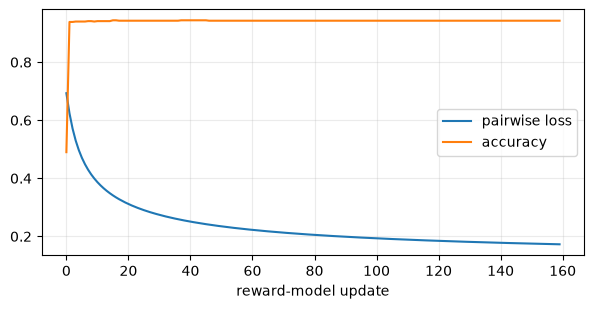

final accuracy: 0.943 cosine to true w: 1.0


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(19)
features = rng.normal(size=(260, 4))
true_w = np.array([1.2, -.8, .5, .2])
pairs = rng.integers(0, len(features), size=(700, 2))
delta = features[pairs[:, 0]] - features[pairs[:, 1]]
labels = ((delta @ true_w + rng.normal(0, .35, len(delta))) > 0).astype(float)
w = np.zeros(4); losses, accuracies = [], []
for _ in range(160):
    logits = delta @ w; probs = 1 / (1 + np.exp(-logits))
    losses.append(-np.mean(labels*np.log(probs+1e-9) + (1-labels)*np.log(1-probs+1e-9)))
    accuracies.append(np.mean((probs > .5) == labels))
    w -= .25 * delta.T @ (probs - labels) / len(labels)

plt.figure(figsize=(7, 3.2)); plt.plot(losses, label="pairwise loss"); plt.plot(accuracies, label="accuracy")
plt.xlabel("reward-model update"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("final accuracy:", round(accuracies[-1], 3), "cosine to true w:", round(w@true_w/(np.linalg.norm(w)*np.linalg.norm(true_w)), 3))


### 曲线怎么读

pairwise loss 下降、held-out preference accuracy 上升才说明 reward model 在学。之后策略回报上升仍可能是 reward hacking，必须人工抽查高分轨迹。

### 调参过程：一次只改变一个因素

- 先按 trajectory/source 分割训练验证集，避免相似片段泄漏。
- 调 reward-model 容量和正则，依据 held-out preference accuracy 选择。
- 策略优化时逐步增加 KL penalty/奖励尺度，并周期补充新偏好数据。

### 失败案例复盘

- 同一轨迹相邻片段跨训练/验证集，准确率虚高。
- reward normalization 在训练中漂移，PPO 目标尺度突然改变。
- 只优化 learned reward，不检查真实任务指标和高分样本。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 训练、验证偏好对必须按轨迹或来源分组，避免近重复泄漏。
- 标签界面要随机交换 A/B 位置，减少位置偏差。
- 持续抽查策略找到的 reward-model 高分样本，这是发现 hacking 的关键。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

交换 score_a 与 score_b，同时把 labels 改为 `1-labels`，验证 loss 应保持一致。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

交换 A/B 后同时把标签变为 `1-label`，logit 从 $R_A-R_B$ 变为其负数，BCE 完全相同。若不翻转标签，语义就变成相反偏好，loss 通常不同。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 偏好模型学习相对顺序，不需要绝对奖励标签。
- Bradley-Terry 概率只取决于片段分数差。
- 策略会利用 reward model 漏洞，因此需要约束和独立人评。
- RLHF 是持续收集、标注、训练、审计的闭环。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么给 $R_A,R_B$ 同时加 100 不改变偏好概率？KL 惩罚能否保证完全没有 reward hacking？

<details>
<summary>展开答案</summary>

概率只依赖差值 $R_A-R_B$，共同平移会抵消。KL 只能限制漂移、降低风险，不能证明 reward model 没有漏洞，仍需数据迭代和独立评估。
</details>


## 17. 与前后章节连接

第 20 章的 self-play 也形成数据生成—训练—改进闭环，但监督信号来自搜索和游戏胜负，而非人类偏好。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

LLM RLHF 还涉及 SFT、token-level KL、PPO/DPO 等；本章项目以可视化环境演示同一核心闭环。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-19) · [← 学习索引](README.md)
